<a href="https://colab.research.google.com/github/ibrahimhalil63aslan/predictive-maintenance-industrial-risk/blob/main/V2_AI4I2020_Data_Preprocessing_and_Exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# -->> AI4I 2020 - Predictive Maintenance Project

**Developer:** İbrahim Halil ASLAN  
**Dataset:** Kaggle - AI4I 2020 Predictive Maintenance  
**Objective:** Analyze industrial machine sensor data to identify potentially risky operating conditions and build an explainable risk analysis framework to support predictive maintenance decisions.

---

### >> What Are We Doing in This Notebook? (Phase 1)

This notebook represents the **first phase of a six-stage predictive maintenance project**.

The main objective of this phase is to import the AI4I 2020 dataset into the Google Colab environment, understand its structure and variables, perform initial data quality checks, and establish a reliable foundation for the **feature engineering, risk scoring, SQL-based analysis, and visualization** stages that follow.

At this stage, no machine learning model is trained. The focus is on **understanding and preparing the raw sensor data** for subsequent engineering analysis.

#### >> Short Workflow:

1. Import the `.csv` dataset into Google Colab
2. Inspect the dataset dimensions and column structure
3. Examine column names and data types
4. Check for missing (`Null`) values
5. Perform an initial inspection using `df.head()`
6. Examine basic statistical properties using `df.describe()`
7. Prepare the data structure for engineering feature creation in the following phases

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np

# Google Drive içindeki tam dosya yolu (MyDrive klasörü)
DATA_PATH = '/content/drive/MyDrive/ai4i2020.csv'

# Veriyi okuma
df = pd.read_csv(DATA_PATH)

# Kontrol
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
display(df.head())

Dataset Shape: 10000 rows, 14 columns



,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [ ]:
# 1. Veri tipleri ve eksik (Null) değer kontrolü
df.info()

# 2. Sayısal sütunların istatistiksel özeti (Min, Max, Ortalama)
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [ ]:
# 1. Kelvin -> Celsius (Santigrat) Dönüşümü
df['air_temp_C'] = df['Air temperature [K]'] - 273.15
df['process_temp_C'] = df['Process temperature [K]'] - 273.15

# 2. Isı Dağılımı / Sıcaklık Farkı (Delta T) Sütunu Türetme
df['temp_diff_C'] = df['process_temp_C'] - df['air_temp_C']

# 3. Mekanik Güç (W) Hesaplama (Power = Torque * Angular Velocity)
# Angular Velocity (rad/s) = rpm * (2 * pi / 60)
df['power_W'] = df['Torque [Nm]'] * (df['Rotational speed [rpm]'] * 2 * np.pi / 60)

# 4. Türetilen yeni mühendislik sütunlarını kontrol etme
print("===>>> Mühendislik Özellikleri Başarıyla Türetildi!\n")
display(df[['Air temperature [K]', 'air_temp_C', 'temp_diff_C', 'power_W']].head())

===>>> Mühendislik Özellikleri Başarıyla Türetildi!



,Air temperature [K],air_temp_C,temp_diff_C,power_W
0,298.1,24.95,10.5,6951.590560
1,298.2,25.05,10.5,6826.722724
2,298.1,24.95,10.4,7749.387543
3,298.2,25.05,10.4,5927.504659
4,298.2,25.05,10.5,5897.816608


In [ ]:
def calculate_risk(row):
    score = 0

    # Kural 1: Isı Dağılımı Yetersizliği (HDF Riski)
    if row['temp_diff_C'] < 8.6 and row['Rotational speed [rpm]'] < 1380:
        score += 35

    # Kural 2: Güç Sınırları Dışında Çalışma (PWF Riski)
    if row['power_W'] < 3500 or row['power_W'] > 9000:
        score += 30

    # Kural 3: Yüksek Takım Aşınması (TWF Riski)
    if row['Tool wear [min]'] > 200:
        score += 25

    # Kural 4: Yüksek Tork / Aşırı Zorlanma
    if row['Torque [Nm]'] > 60:
        score += 10

    return min(score, 100)

# 1. Fonksiyonu tüm satırlara uygula
df['risk_score'] = df.apply(calculate_risk, axis=1)

# 2. Riskli motorları filtrele (Risk skoru 50 ve üzeri olanlar)
riskli_motorlar = df[df['risk_score'] >= 50]

print(f"=> Toplam Tespit Edilen Riskli Kayıt Sayısı: {len(riskli_motorlar)} <=")
display(riskli_motorlar[['Product ID', 'temp_diff_C', 'power_W', 'Tool wear [min]', 'risk_score']].head())

=> Toplam Tespit Edilen Riskli Kayıt Sayısı: 20 <=


,Product ID,temp_diff_C,power_W,Tool wear [min],risk_score
847,L48027,11.0,1661.357971,213,55
3943,L51123,9.1,9310.748619,205,65
4119,L51299,8.6,6257.790767,208,60
4120,M18980,8.6,6671.569935,210,60
4121,M18981,8.6,6827.644258,213,60


In [ ]:
riskli_motorlar.to_csv('riskli_motorlar.csv', index=False)

In [ ]:
import sqlite3
import pandas as pd

# 1. Bellekte/Dosyada SQLite Veritabanı bağlantısı oluşturma
conn = sqlite3.connect('predictive_maintenance.db')

# 2. DataFrame'imizi doğrudan SQLite tablosuna yazma
df.to_sql('motor_measurements', conn, if_exists='replace', index=False)

# 3. SQL Sorgusu (SQLite Standartlarına Uygun Çift Tırnak Kullanımı)
sql_query = """
SELECT
    "Product ID",
    "Type",
    round(temp_diff_C, 2) AS delta_T,
    round(power_W, 2) AS power_watts,
    "Tool wear [min]" AS tool_wear,
    risk_score
FROM motor_measurements
WHERE risk_score >= 50
ORDER BY risk_score DESC, power_W DESC
LIMIT 10;
"""

# 4. SQL Sorgusunu çalıştırıp sonucu Pandas DataFrame olarak alma
sql_result = pd.read_sql_query(sql_query, conn)

print("⚡ SQLite Veritabanı Sorgu Sonucu (Top 10 Riskli Motor):")
display(sql_result)

⚡ SQLite Veritabanı Sorgu Sonucu (Top 10 Riskli Motor):


,Product ID,Type,delta_T,power_watts,tool_wear,risk_score
0,L51597,L,7.8,9548.56,80,75
1,M19202,M,8.1,9170.18,111,75
2,L51434,L,8.4,9143.29,114,75
3,L51563,L,7.8,8903.17,229,70
4,L51909,L,8.4,8342.60,215,70
5,H35323,H,9.5,9327.30,208,65
6,M20254,M,9.5,9317.02,234,65
7,L51123,L,9.1,9310.75,205,65
8,L54263,L,9.7,9163.90,209,65
9,L51823,L,8.2,7514.77,228,60


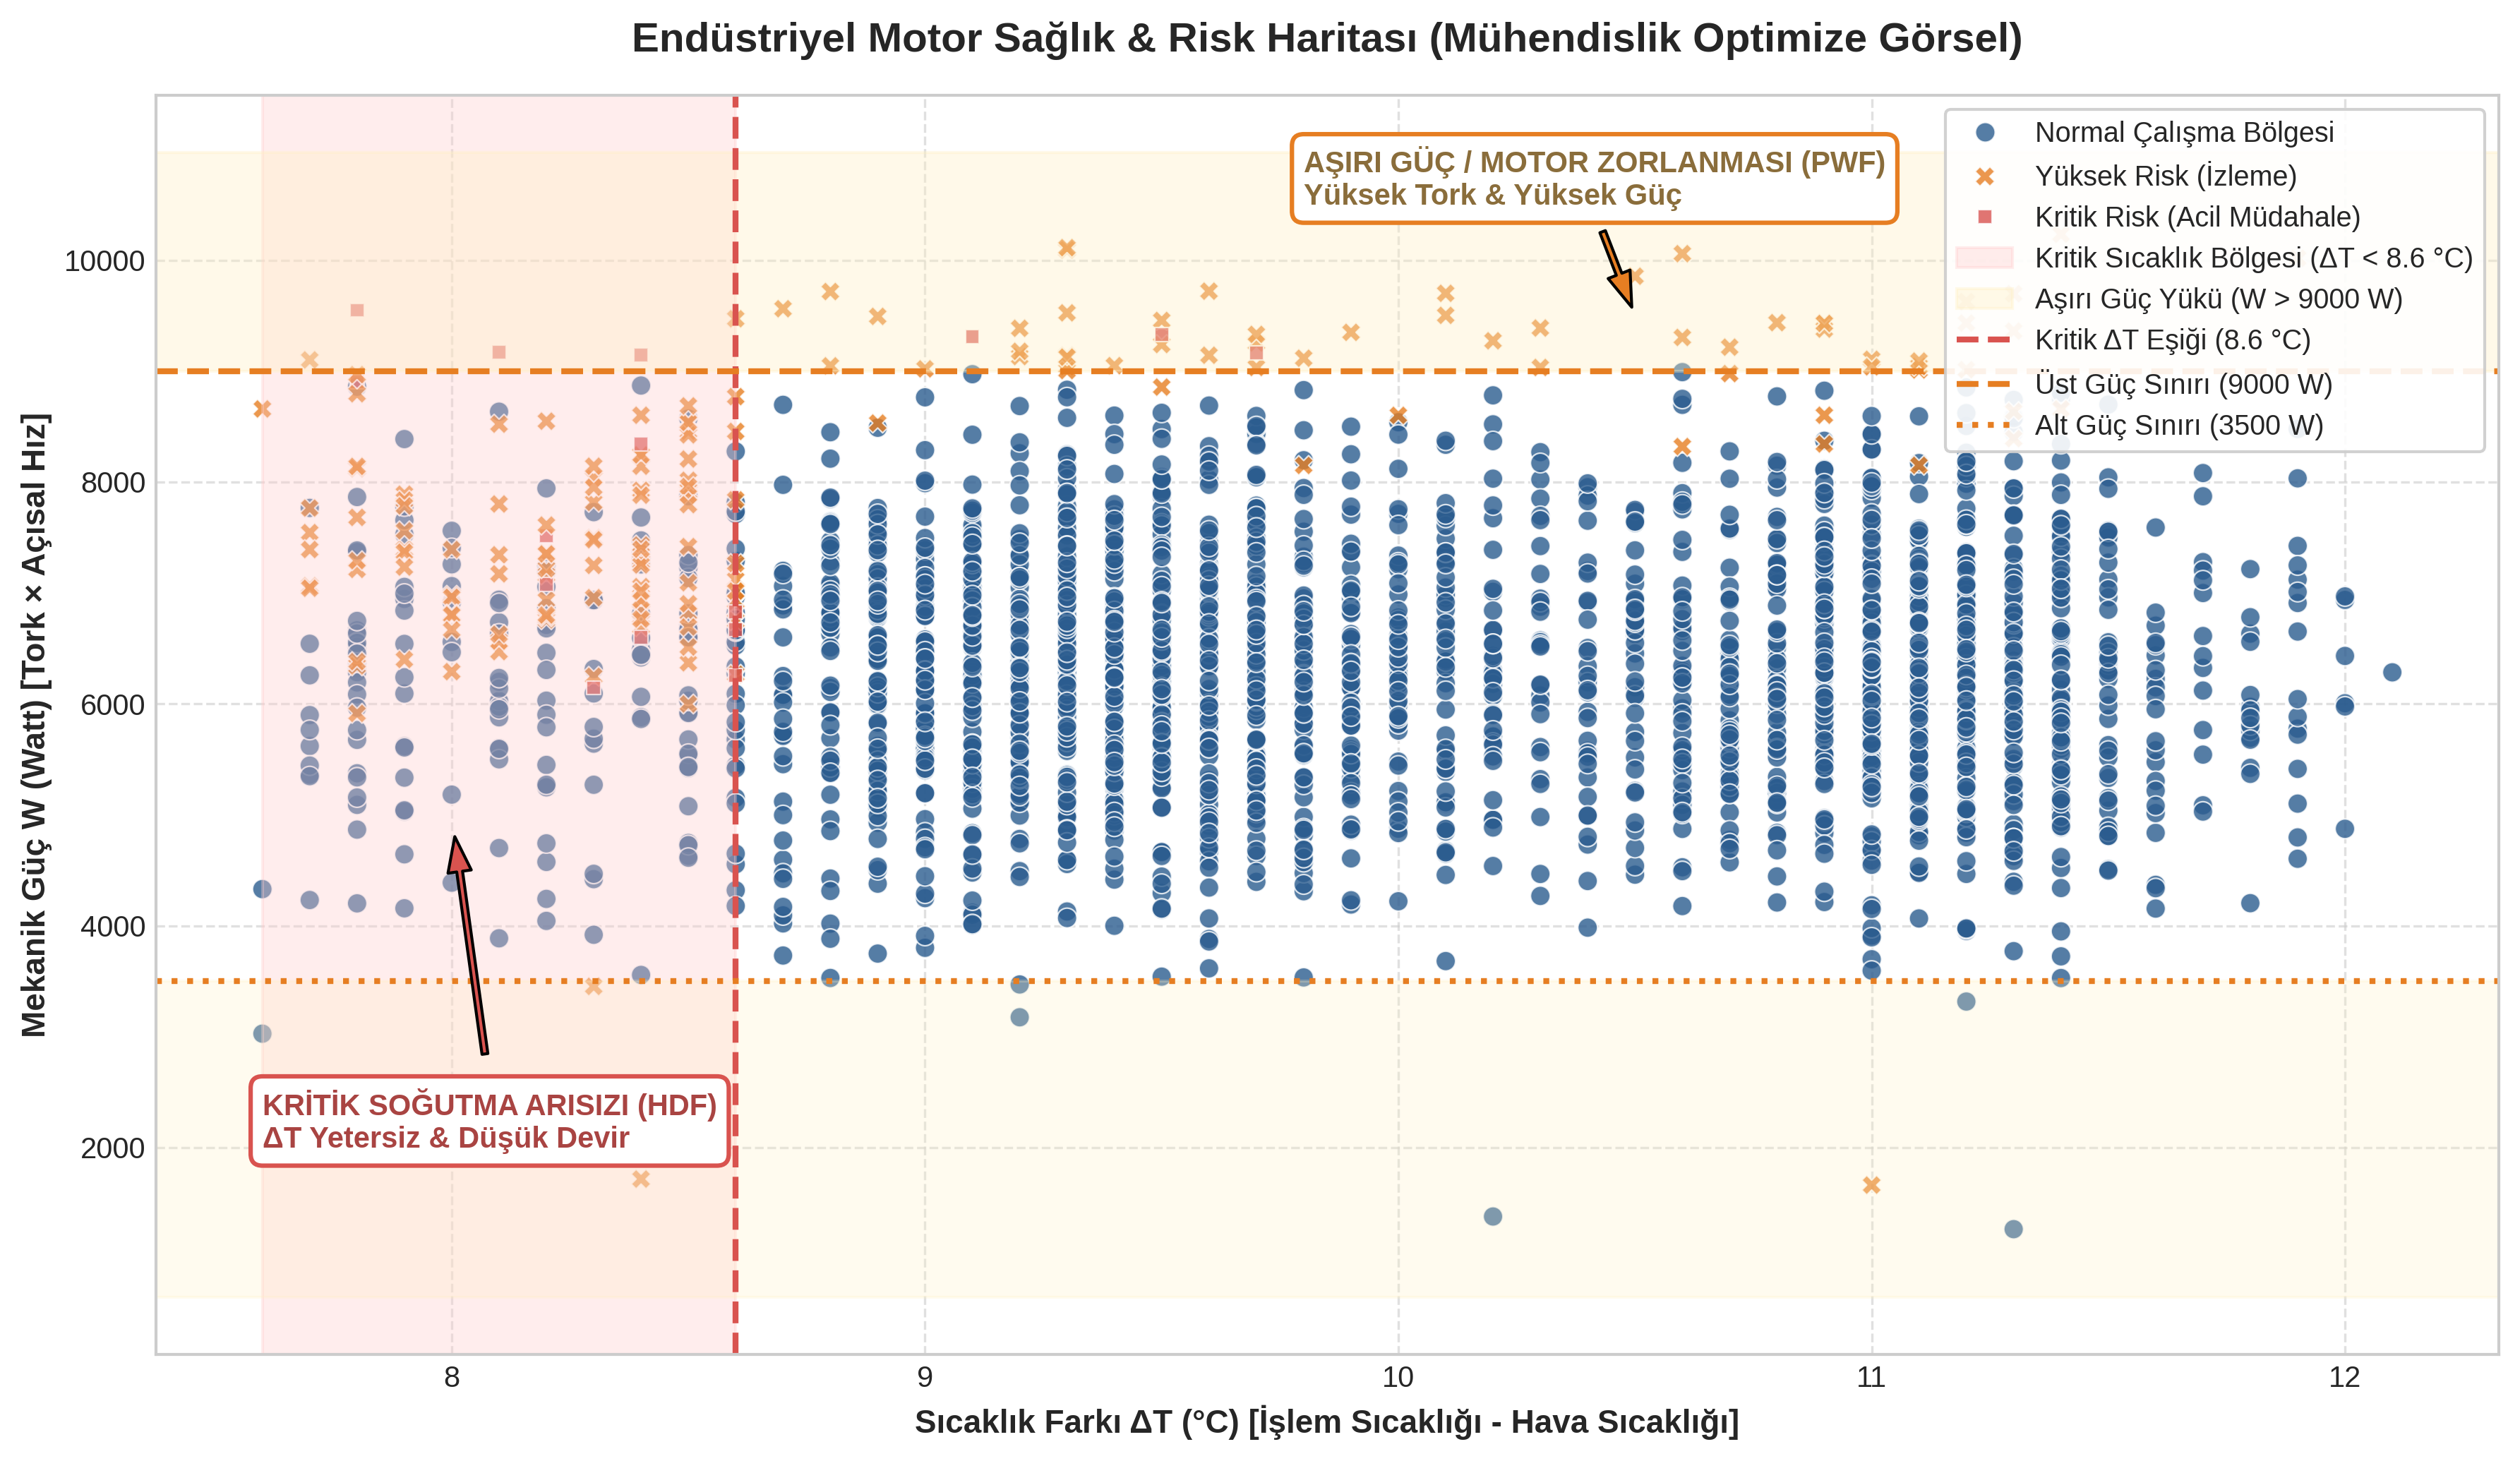

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import os

# 1. Risk Kategorizasyonu Sütunu Oluşturma
def assign_risk_category(score):
    if score >= 60:
        return 'Kritik Risk (Acil Müdahale)'
    elif score >= 35:
        return 'Yüksek Risk (İzleme)'
    else:
        return 'Normal Çalışma Bölgesi'

df['Risk_Kategorisi'] = df['risk_score'].apply(assign_risk_category)

# 2. Grafik Stili ve Çerçeve
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(12, 7), dpi=300)

palette = {
    'Normal Çalışma Bölgesi': '#2b5c8f',
    'Yüksek Risk (İzleme)': '#e67e22',
    'Kritik Risk (Acil Müdahale)': '#d9534f'
}

# Normal noktaları hafif alt-örnekleyerek risk noktalarını öne çıkarma
df_normal = df[df['Risk_Kategorisi'] == 'Normal Çalışma Bölgesi'].sample(n=min(2500, len(df[df['Risk_Kategorisi'] == 'Normal Çalışma Bölgesi'])), random_state=42)
df_risk = df[df['Risk_Kategorisi'] != 'Normal Çalışma Bölgesi']
df_plot = pd.concat([df_normal, df_risk])

# 3. Saçılım Grafiği (Scatter Plot)
sns.scatterplot(
    data=df_plot,
    x='temp_diff_C',
    y='power_W',
    hue='Risk_Kategorisi',
    style='Risk_Kategorisi',
    palette=palette,
    alpha=0.8,
    s=45,
    ax=ax
)

# 4. Kritik Risk Alanlarının Renkli Gölgelendirilmesi
ax.axvspan(df['temp_diff_C'].min(), 8.6, color='#ffcccc', alpha=0.35, label='Kritik Sıcaklık Bölgesi (ΔT < 8.6 °C)')
ax.axhspan(9000, df['power_W'].max() + 500, color='#fff0c2', alpha=0.35, label='Aşırı Güç Yükü (W > 9000 W)')
ax.axhspan(df['power_W'].min() - 500, 3500, color='#fff0c2', alpha=0.25)

# 5. Kritik Referans Çizgileri
ax.axvline(x=8.6, color='#d9534f', linestyle='--', linewidth=2, label='Kritik ΔT Eşiği (8.6 °C)')
ax.axhline(y=9000, color='#e67e22', linestyle='--', linewidth=2, label='Üst Güç Sınırı (9000 W)')
ax.axhline(y=3500, color='#e67e22', linestyle=':', linewidth=2, label='Alt Güç Sınırı (3500 W)')

# 6. Doğrudan İş Problemine Odaklanan Açıklama Kutuları (Annotations)
ax.annotate('KRİTİK SOĞUTMA ARISIZI (HDF)\nΔT Yetersiz & Düşük Devir',
            xy=(8.0, 5000), xytext=(7.6, 2000),
            arrowprops=dict(facecolor='#d9534f', shrink=0.08, width=2, headwidth=8),
            fontsize=10, fontweight='bold', color='#a94442',
            bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#d9534f", lw=1.5))

ax.annotate('AŞIRI GÜÇ / MOTOR ZORLANMASI (PWF)\nYüksek Tork & Yüksek Güç',
            xy=(10.5, 9500), xytext=(9.8, 10500),
            arrowprops=dict(facecolor='#e67e22', shrink=0.08, width=2, headwidth=8),
            fontsize=10, fontweight='bold', color='#8a6d3b',
            bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#e67e22", lw=1.5))

# Title & Axis
ax.set_title('Endüstriyel Motor Sağlık & Risk Haritası (Mühendislik Optimize Görsel)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Sıcaklık Farkı ΔT (°C) [İşlem Sıcaklığı - Hava Sıcaklığı]', fontsize=11, fontweight='bold')
ax.set_ylabel('Mekanik Güç W (Watt) [Tork × Açısal Hız]', fontsize=11, fontweight='bold')

ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9, fontsize=9.5)

plt.tight_layout()

# Görseli Kaydetme
os.makedirs('images', exist_ok=True)
plt.savefig('images/temperature_vs_power.png', dpi=300)
plt.show()

In [ ]:
# 1. Arızalı ve normal durumların sayısal özeti
failures = df[df['Machine failure'] == 1]
normal = df[df['Machine failure'] == 0]

print(f"Toplam Arıza Sayısı: {len(failures)} / {len(df)}")
print("\nArızalı Durumlarda Sensör Ortalama Değerleri:")
display(failures[['Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'temp_diff_C']].mean())

print("\nNormal Durumlarda Sensör Ortalama Değerleri:")
display(normal[['Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'temp_diff_C']].mean())

Toplam Arıza Sayısı: 339 / 10000

Arızalı Durumlarda Sensör Ortalama Değerleri:


,0
Rotational speed [rpm],1496.486726
Torque [Nm],50.168142
Tool wear [min],143.781711
temp_diff_C,9.403835



Normal Durumlarda Sensör Ortalama Değerleri:


,0
Rotational speed [rpm],1540.260014
Torque [Nm],39.629655
Tool wear [min],106.693717
temp_diff_C,10.021571


/tmp/ipykernel_3581/2087392631.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Machine failure', y='Tool wear [min]', palette='Set2')


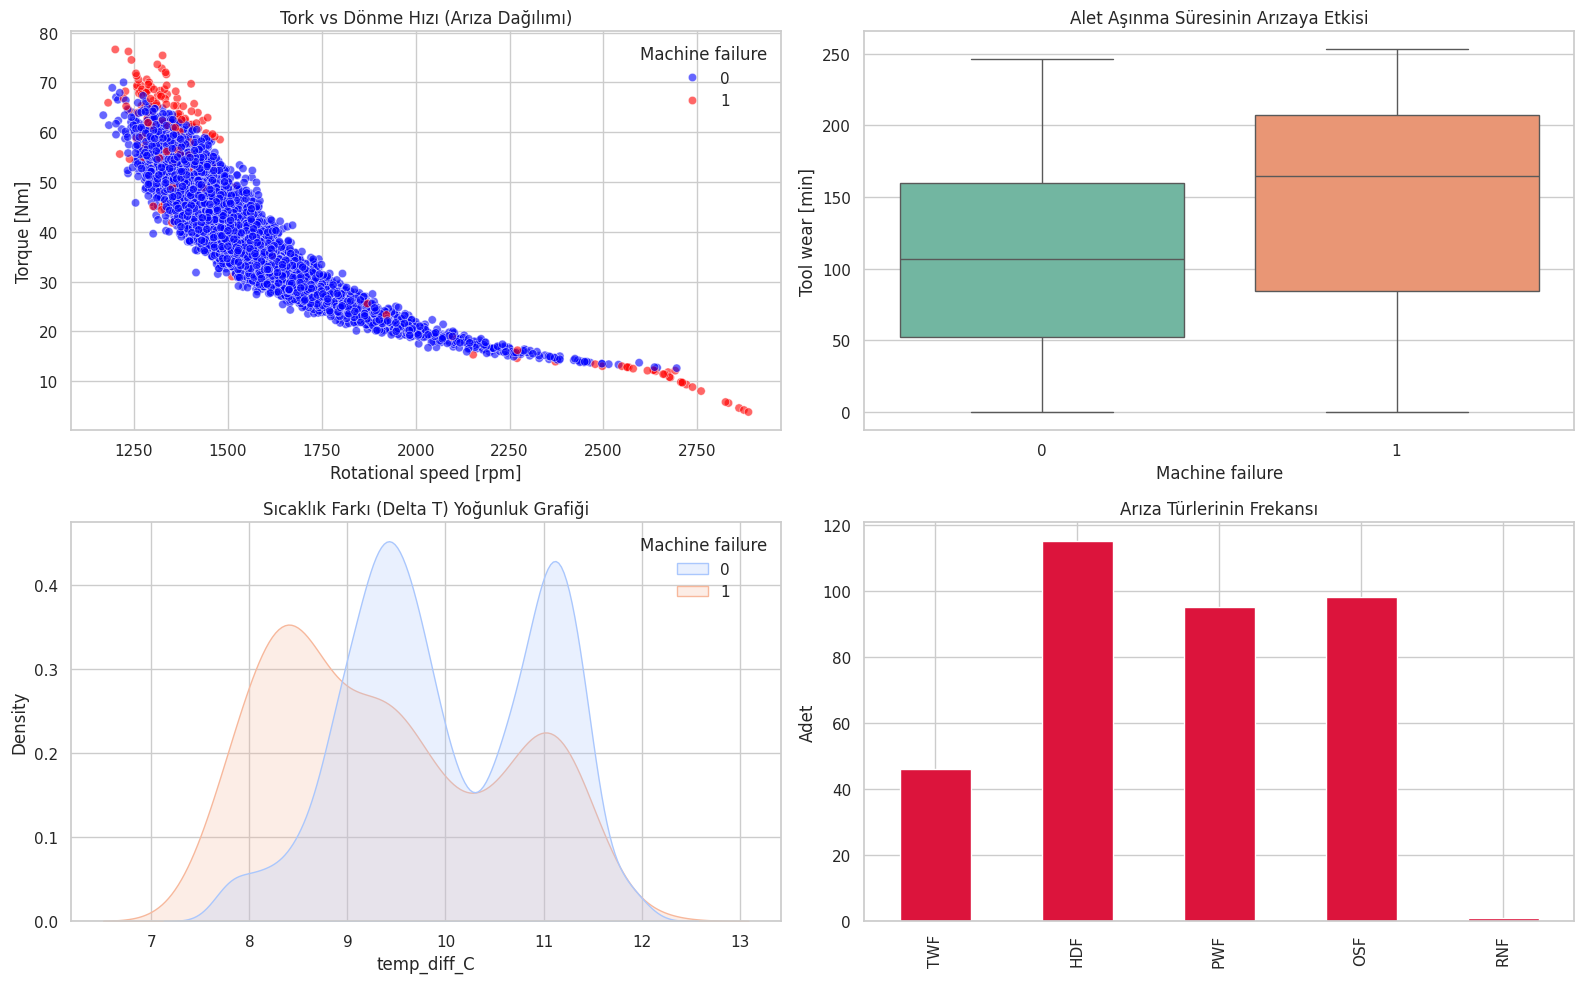

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Grafik stilini ayarlayalım
sns.set_theme(style="whitegrid")
plt.figure(figsize=(16, 10))

# 1. Tork ve Dönme Hızı İlişkisi (Arıza Dağılımı)
plt.subplot(2, 2, 1)
sns.scatterplot(
    data=df,
    x='Rotational speed [rpm]',
    y='Torque [Nm]',
    hue='Machine failure',
    palette={0: 'blue', 1: 'red'},
    alpha=0.6
)
plt.title('Tork vs Dönme Hızı (Arıza Dağılımı)')

# 2. Alet Aşınması (Tool Wear) ve Arıza İlişkisi
plt.subplot(2, 2, 2)
sns.boxplot(data=df, x='Machine failure', y='Tool wear [min]', palette='Set2')
plt.title('Alet Aşınma Süresinin Arızaya Etkisi')

# 3. Sıcaklık Farkı (Delta T) Yoğunluk Grafiği
plt.subplot(2, 2, 3)
sns.kdeplot(data=df, x='temp_diff_C', hue='Machine failure', common_norm=False, fill=True, palette='coolwarm')
plt.title('Sıcaklık Farkı (Delta T) Yoğunluk Grafiği')

# 4. Arıza Türlerinin Sayısal Dağılımı
plt.subplot(2, 2, 4)
failure_types = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
df[df['Machine failure'] == 1][failure_types].sum().plot(kind='bar', color='crimson')
plt.title('Arıza Türlerinin Frekansı')
plt.ylabel('Adet')

plt.tight_layout()
plt.show()

### 3. HDF (Isı Dağılım Arızası) ve Kritik Sıcaklık Eşiği Analizi

**Amaç:**
Veri setinde en sık karşılaşılan arıza türü olan **HDF (Heat Dissipation Failure)** durumlarını detaylıca incelemek.
İşlem sıcaklığı ile hava sıcaklığı arasındaki farkın (`temp_diff_C`) hangi kritik eşik değerinin altına düştüğünde ısı dağılım arızasının tetiklendiğini sayısal olarak tespit etmek.

**Yapılacak Adımlar:**
1. Yalnızca `HDF == 1` olan arızalı satırları filtrelemek.
2. HDF gerçekleşen anlardaki sıcaklık değerlerinin özet istatistiklerini (`describe()`) çıkarmak.
3. Isı dağılım arızasının görüldüğü maksimum sıcaklık farkını (kritik eşik) belirlemek.

In [ ]:
# 1. Sadece HDF arızası yaşanan satırları filtreleyelim
hdf_failures = df[df['HDF'] == 1]

# 2. HDF arızasındaki sıcaklık değerlerinin detaylı istatistikleri
print(f"Toplam HDF Arıza Sayısı: {len(hdf_failures)}")
print("\nHDF Arızası Yaşanan Durumlarda Sıcaklık Değerleri Özeti:")
display(hdf_failures[['Air temperature [K]', 'Process temperature [K]', 'temp_diff_C']].describe())

# 3. HDF için kritik eşik (maksimum sıcaklık farkı) değeri
max_temp_diff_hdf = hdf_failures['temp_diff_C'].max()
print(f"\n--> HDF Arızasının Görüldüğü En Yüksek Sıcaklık Farkı (Kritik Eşik): {max_temp_diff_hdf:.2f} °C")


Toplam HDF Arıza Sayısı: 115

HDF Arızası Yaşanan Durumlarda Sıcaklık Değerleri Özeti:


,Air temperature [K],Process temperature [K],temp_diff_C
count,115.000000,115.000000,115.000000
mean,302.560870,310.788696,8.227826
std,0.601853,0.644513,0.282392
min,300.800000,309.400000,7.600000
25%,302.100000,310.300000,8.000000
50%,302.500000,310.700000,8.300000
75%,303.050000,311.300000,8.500000
max,303.700000,312.200000,8.600000



--> HDF Arızasının Görüldüğü En Yüksek Sıcaklık Farkı (Kritik Eşik): 8.60 °C


### 4. OSF (Aşırı Yüklenme Arızası) ve Mekanik Sınır Analizi

**Amaç:**
Veri setinde ikinci en sık görülen **OSF (Overstrain Failure)** arızasının arkasındaki mekanik sebepleri incelemek. Tork ve alet aşınma süresinin aşırı yüklenmeye etkisini tespit etmek.

**Yapılacak Adımlar:**
1. Yalnızca `OSF == 1` olan satırları filtrelemek.
2. OSF anındaki Tork (`Torque [Nm]`) ve Alet Aşınması (`Tool wear [min]`) değerlerinin ortalama ve maksimum seviyelerini incelemek.

In [ ]:
# 1. Sadece OSF arızası yaşanan satırları filtreleyelim
osf_failures = df[df['OSF'] == 1]

# 2. OSF arızasındaki Tork ve Alet Aşınması istatistikleri
print(f"Toplam OSF Arıza Sayısı: {len(osf_failures)}")
print("\nOSF Arızası Yaşanan Durumlarda Mekanik Değerlerin Özeti:")
display(osf_failures[['Torque [Nm]', 'Tool wear [min]', 'Rotational speed [rpm]']].describe())

# 3. OSF görülen durumdaki minimum Tork ve Alet Aşınması değerleri
print(f"\n--> OSF Arızasında Görülen En Düşük Tork: {osf_failures['Torque [Nm]'].min():.2f} Nm")
print(f"--> OSF Arızasında Görülen En Düşük Alet Aşınması: {osf_failures['Tool wear [min]'].min()} dk")

Toplam OSF Arıza Sayısı: 98

OSF Arızası Yaşanan Durumlarda Mekanik Değerlerin Özeti:


,Torque [Nm],Tool wear [min],Rotational speed [rpm]
count,98.000000,98.000000,98.000000
mean,58.370408,207.693878,1350.326531
std,5.943587,15.811002,61.250841
min,46.300000,172.000000,1181.000000
25%,53.825000,197.000000,1313.000000
50%,57.700000,207.000000,1360.500000
75%,61.675000,216.000000,1382.250000
max,75.400000,253.000000,1515.000000



--> OSF Arızasında Görülen En Düşük Tork: 46.30 Nm
--> OSF Arızasında Görülen En Düşük Alet Aşınması: 172 dk


### 5. Mekanik Yük (Tool Wear x Torque) Öznitelik Türetimi

**Amaç:**
OSF (Aşırı Yüklenme) arızasının Alet Aşınması ve Tork değişkenlerinin bileşimiyle ortaya çıktığını tespit ettik.
Bu mekanik etkileşimi doğrudan temsil edecek `mechanical_load` (Mekanik Yük = Tool wear * Torque) sütununu oluşturmak.

**Yapılacak Adımlar:**
1. `df['mechanical_load'] = df['Tool wear [min]'] * df['Torque [Nm]']` hesaplamasını yapmak.
2. OSF arızası gerçekleşen anlardaki minimum ve ortalama mekanik yük değerini tespit ederek kritik eşiği belirlemek.

In [ ]:
# 1. Mekanik Yük (Tool Wear * Torque) sütununu oluşturalım
df['mechanical_load'] = df['Tool wear [min]'] * df['Torque [Nm]']

# 2. OSF arızasındaki mekanik yük değerlerini inceleyelim
osf_failures = df[df['OSF'] == 1]

print(f"OSF Arızasında Görülen En Düşük Mekanik Yük: {osf_failures['mechanical_load'].min():.2f} min*Nm")
print(f"OSF Arızasında Ortalama Mekanik Yük: {osf_failures['mechanical_load'].mean():.2f} min*Nm")
print(f"Normal Durumda Ortalama Mekanik Yük: {df[df['OSF'] == 0]['mechanical_load'].mean():.2f} min*Nm")

OSF Arızasında Görülen En Düşük Mekanik Yük: 11003.20 min*Nm
OSF Arızasında Ortalama Mekanik Yük: 12066.99 min*Nm
Normal Durumda Ortalama Mekanik Yük: 4237.94 min*Nm


Kural Bazlı Bakım Eşiği (Early Warning):

Tork ve alet aşınmasının bileşik etkisi 11.000 min*Nm sınırını geçtiğinde makine doğrudan OSF risk bölgesine giriyor.

# Aksiyon: 11.000 min*Nm değeri, kural bazlı erken uyarı ve önleyici bakım tetikleyicisi olarak koda/modele tanımlanabilir.